# Lab 6: Preprocessing, PCA and ISOMAP

In [1]:
from numpy.linalg import eig
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

engdata = pd.read_csv("./engdata.txt")
pdata = engdata.loc[:, ["Age", "Salary"]]

In [2]:
pdata = pdata.drop_duplicates()

In [3]:
scaler = StandardScaler()
scaler = scaler.fit(pdata)
transformed = pd.DataFrame(scaler.transform(pdata), columns=["Age", "Salary"])

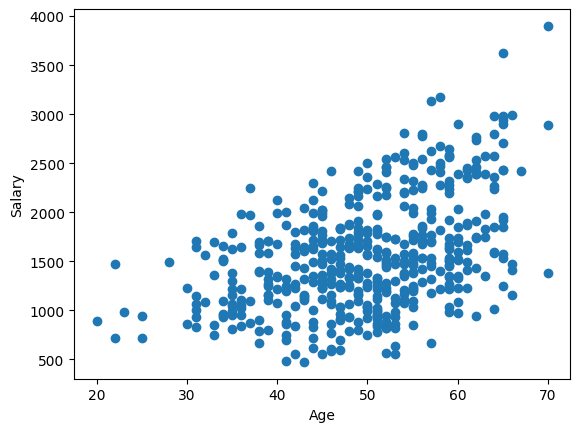

In [4]:
plt.scatter(pdata.Age, pdata.Salary)
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

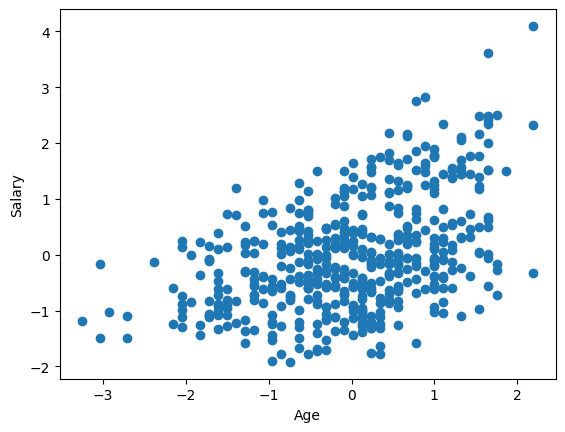

In [5]:
plt.scatter(transformed.Age, transformed.Salary)
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

In [6]:
data_sample = pdata.sample(n=150, random_state=1, replace=True)

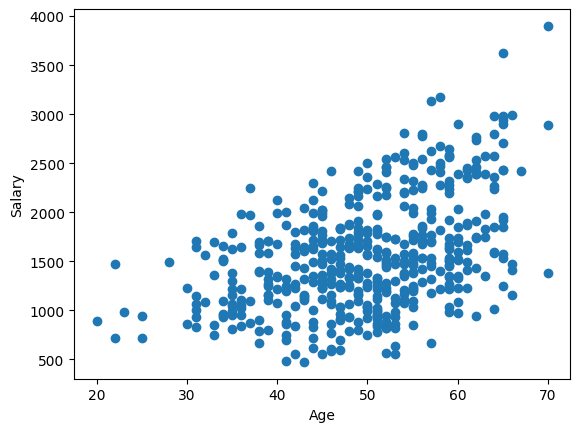

In [7]:
plt.scatter(pdata.Age, pdata.Salary)
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

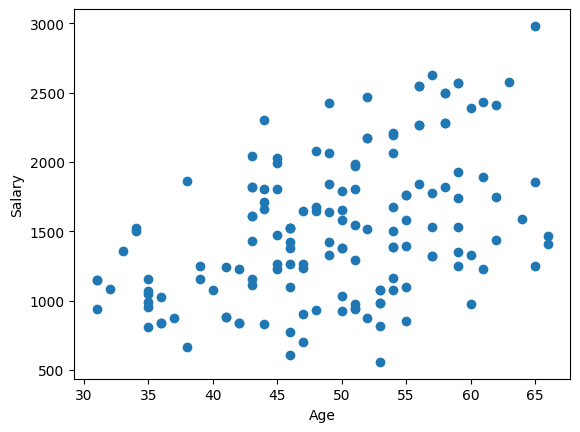

In [8]:
plt.scatter(data_sample.Age, data_sample.Salary)
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

In [9]:
discAge = pd.cut(pdata.Age, [0, 10, 20, 30, 40, 50, 60, 70, 80])
discSalary = pd.cut(pdata.Salary, pd.interval_range(start=0, freq=400, end=4000))

In [10]:
X = [1, 0, -1, 0, -1, 1]
Y = [0, 1, 1, -1, 0, -1]
Z = [-1, -1, 0, 1, 1, 0]
labels = ["x1", "x2", "x3", "x4", "x5", "x6"]
pdata = pd.DataFrame({"X": X, "Y": Y, "Z": Z}, index=labels)

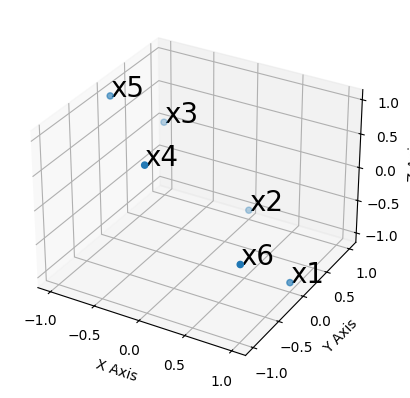

In [11]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(pdata.X, pdata.Y, pdata.Z)
for i in range(len(pdata.index)):
    ax.text(pdata.loc[labels[i], "X"], pdata.loc[labels[i], "Y"], pdata.loc[labels[i], "Z"], '%s' % (str(labels[i])), size=20, zorder=1) 
ax.set_xlabel('X Axis')
ax.set_ylabel('Y Axis')
ax.set_zlabel('Z Axis')
plt.show()

In [12]:
engdata = pd.read_csv("./engdata.txt")
location = engdata.Location
engdata = engdata.drop(["Location"], axis=1)

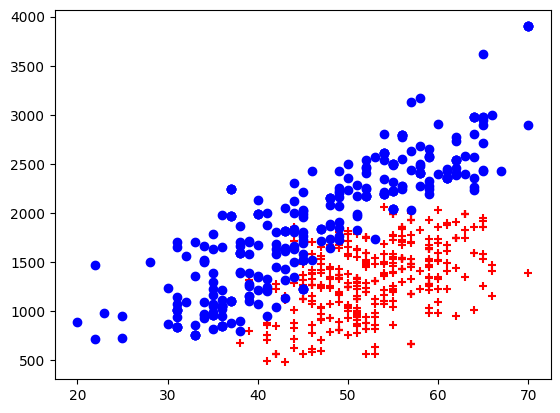

                   Age    Salary  YearsOfStudy   WorkExp
Age           1.000000  0.484701     -0.804492  0.975779
Salary        0.484701  1.000000     -0.365390  0.471907
YearsOfStudy -0.804492 -0.365390      1.000000 -0.785106
WorkExp       0.975779  0.471907     -0.785106  1.000000


In [13]:
plt.scatter(engdata[(location == "EU")].Age, engdata[(location == "EU")].Salary, c="red", marker="+")
plt.scatter(engdata[(location == "US")].Age, engdata[(location == "US")].Salary, c="blue", marker="o")
plt.show()
print(engdata.corr())

In [14]:
from sklearn.decomposition import PCA
scaler = StandardScaler()
scaler = scaler.fit(engdata)
transformed = pd.DataFrame(scaler.transform(engdata), columns=engdata.columns)
pca = PCA()
pca = pca.fit(transformed)
pca_transformed = pca.transform(transformed)
eigenvalues = pca.explained_variance_
eigenvectors = pca.components_

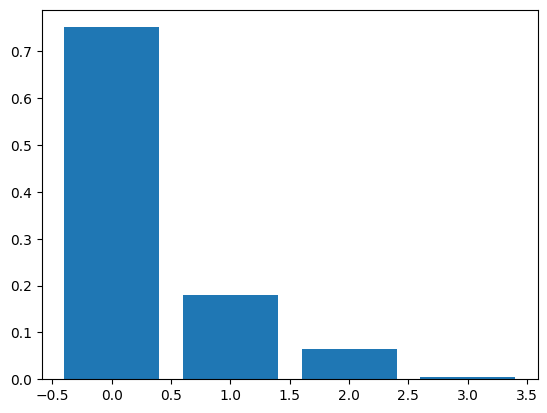

In [15]:
plt.bar(range(len(eigenvalues)), eigenvalues/sum(eigenvalues))
plt.show()

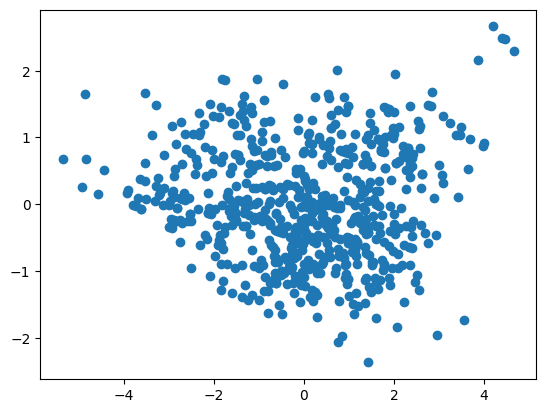

In [16]:
pca = PCA(n_components=2)
pca = pca.fit(transformed)
pca_transformed = pd.DataFrame(pca.transform(transformed))
plt.scatter(pca_transformed.loc[:, 0], pca_transformed.loc[:, 1])
plt.show()

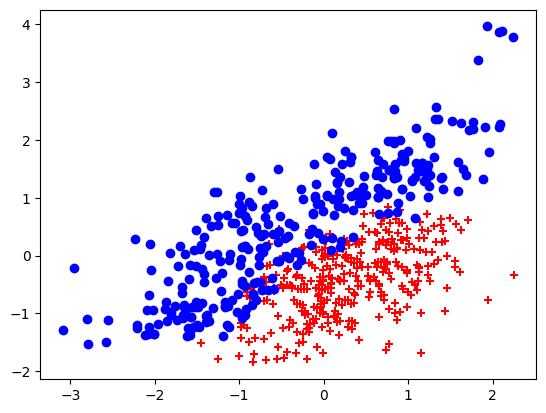

In [17]:
pca_inverse = pd.DataFrame(pca.inverse_transform(pca_transformed.to_numpy()), columns=engdata.columns)
plt.scatter(pca_inverse[(location == "EU")].Age, pca_inverse[(location == "EU")].Salary, c="red", marker="+")
plt.scatter(pca_inverse[(location == "US")].Age, pca_inverse[(location == "US")].Salary, c="blue", marker="o")
plt.show()

In [18]:
info_loss = (eigenvalues[2] + eigenvalues[3]) / sum(eigenvalues)
print(info_loss)

0.06956129680531473


In [19]:
srdata = pd.read_csv("./srdata.txt")

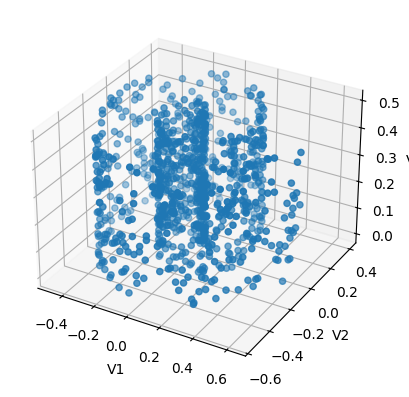

In [20]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(srdata.V1, srdata.V2, srdata.V3)
ax.set_xlabel('V1')
ax.set_ylabel('V2')
ax.set_zlabel('V3')
plt.show()

In [21]:
from sklearn.manifold import Isomap
isomap = Isomap(n_neighbors = 4, n_components = 2)
isomap = isomap.fit(srdata)
transformed = pd.DataFrame(isomap.transform(srdata))

In [22]:
colors = [i - min(transformed.loc[:, 0].tolist()) + 1 for i in transformed.loc[:, 0].tolist()]

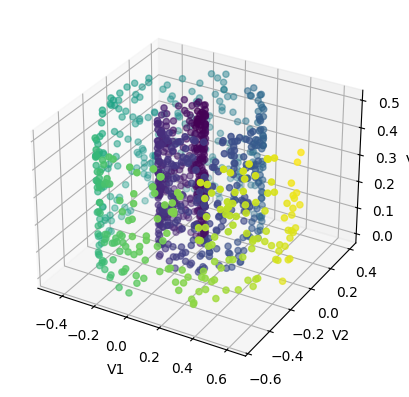

In [23]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(srdata.V1, srdata.V2, srdata.V3, c=colors)
ax.set_xlabel('V1')
ax.set_ylabel('V2')
ax.set_zlabel('V3')
plt.show()

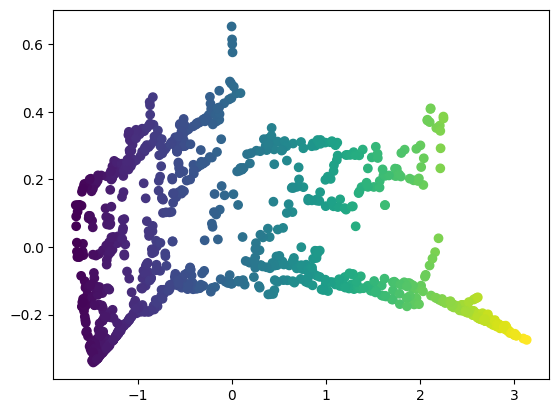

In [24]:
plt.scatter(transformed.loc[:, 0], transformed.loc[:, 1], c=colors)
plt.show()